In [ ]:
# Import the library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



In [2]:
# Load the data

df = pd.read_csv("../data/CO2_data.csv")
df.head()

,T [C],P_vap [kPa],H_vap [J/g],rho_vap [g/cm3],rho_liq [g/cm3]
0,-56.6,518.3,NaN,NaN,1.179
1,-56.0,531.8,NaN,NaN,1.177
2,-54.0,579.1,NaN,NaN,1.169
3,-52.0,629.6,NaN,NaN,1.162
4,-50.0,683.4,NaN,NaN,1.155


In [3]:
# Information about the data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 72 entries, 0 to 71
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   T [C]            72 non-null     float64
 1   P_vap [kPa]      72 non-null     float64
 2   H_vap [J/g]      57 non-null     float64
 3   rho_vap [g/cm3]  57 non-null     float64
 4   rho_liq [g/cm3]  72 non-null     float64
dtypes: float64(5)
memory usage: 2.9 KB


In [4]:
df.describe()

,T [C],P_vap [kPa],H_vap [J/g],rho_vap [g/cm3],rho_liq [g/cm3]
count,72.000000,72.000000,57.000000,57.000000,72.000000
mean,-7.696944,3318.288889,208.747544,0.132168,0.924410
std,24.977866,2016.721511,70.314376,0.093078,0.159318
min,-56.600000,518.300000,0.000000,0.038460,0.464100
25%,-25.837500,1672.000000,169.100000,0.063140,0.831700
50%,-6.115000,2954.500000,227.300000,0.101300,0.941800
75%,13.057500,4830.750000,264.500000,0.171700,1.021725
max,31.100000,7391.000000,292.900000,0.464100,1.179000


In [5]:
# Dropping NaN values
df = df.dropna(subset=['H_vap [J/g]', 'rho_vap [g/cm3]'])
df.shape

(57, 5)

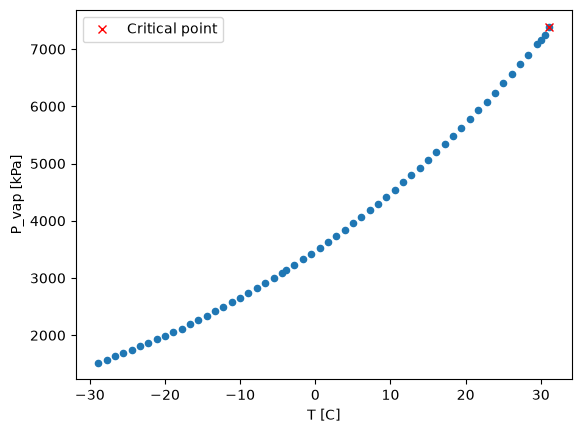

In [6]:
# Plot the critical point where H_vap is 0

df.plot.scatter(x='T [C]', y='P_vap [kPa]')
T_critical = df[df['H_vap [J/g]']==0]['T [C]'].values
P_critical = df[df['H_vap [J/g]']==0]['P_vap [kPa]'].values

plt.plot(T_critical, P_critical, 'rx', label='Critical point')
plt.legend()
plt.show()

<Axes: xlabel='T [C]', ylabel='H_vap [J/g]'>

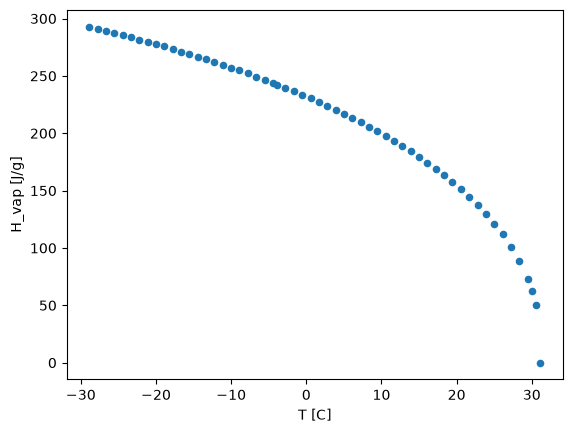

In [7]:
# plot the enthalpy of vaporization which is the amount of energy that certain amount of liquid needs to be transformed into a vapor.
df.plot.scatter(x='T [C]', y='H_vap [J/g]')

It can be clearly seen that the maximum temperature in the dataset correspond to the critical point (i.e., when the enthalpy of vaporization is zero)!

R2 score:  0.9753951691214063
RMSE:  4311.083535119679


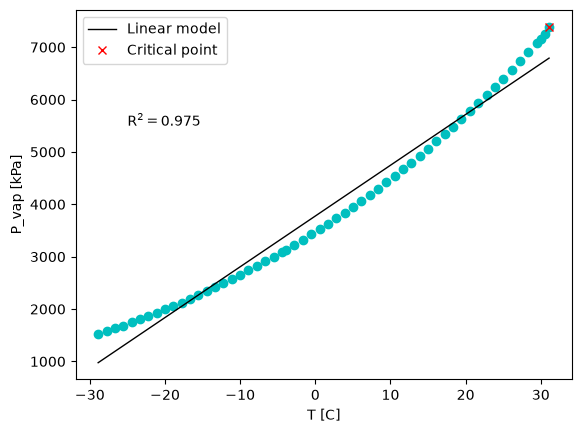

In [27]:
# fit linear model for baseline

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
Ps = df['P_vap [kPa]'].to_numpy().reshape(-1,1)
Ts = df['T [C]'].to_numpy().reshape(-1,1)

x_pred = np.linspace(min(Ts), max(Ts), 100)
model_lr = LinearRegression().fit(Ts, Ps)
y_pred = model_lr.predict(x_pred)
print("R2 score: ", model_lr.score(Ts, Ps))
print("RMSE: ", np.sqrt(mean_squared_error(Ts,  model_lr.predict(Ts))))

#plot the graph
plt.figure()
plt.plot(Ts, Ps, 'co')
plt.plot(x_pred, y_pred, 'k', linewidth=1, label='Linear model')
plt.plot(T_critical, P_critical, 'rx', label='Critical point')
plt.text(-25, 5500, 'R$^2 = $' + str(np.round(model_lr.score(Ts, Ps), 3)))
plt.xlabel('T [C]')
plt.ylabel('P_vap [kPa]')
plt.legend()
plt.show()


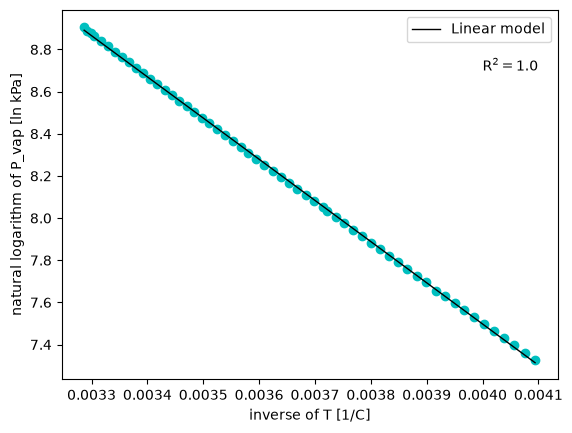

In [9]:
# Using the Clausius-Clayperon equation

ln_P = np.log(Ps)
inv_T = 1/(Ts + 273.15)

linear_regression = LinearRegression().fit(inv_T, ln_P)

x_pred = np.linspace(min(inv_T), max(inv_T), 100)
y_pred = linear_regression.predict(x_pred)
R2 = linear_regression.score(inv_T, ln_P)


plt.figure()
plt.plot(inv_T, ln_P, 'co')
plt.plot(x_pred, y_pred,'k', linewidth=1, label='Linear model')
plt.text(0.004, 8.7, 'R$^2 = $' + str(np.round(R2, 3)))
plt.xlabel('inverse of T [1/C]')
plt.ylabel('natural logarithm of P_vap [ln kPa]')
plt.legend()
plt.show()

In [26]:
print("Coefficient: ", linear_regression.coef_)
print("Intercept: ", linear_regression.intercept_)

y_hat = linear_regression.predict(inv_T)   # 57 predictions, one per real point
print(y_hat.shape, ln_P.shape)              # both should be (57, 1)
rmse = np.sqrt(mean_squared_error(ln_P, y_hat))
print("RMSE: ", rmse)

Coefficient:  [[-1953.98367395]]
Intercept:  [15.31346783]
(57, 1) (57, 1)
RMSE:  0.0060700695077152205


C:\Users\user\AppData\Local\Temp\ipykernel_18220\4028291752.py:18: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "co" (-> color='c'). The keyword argument will take precedence.
  plt.plot(neg_Hvaps_T, ln_P, 'co', color = "green")


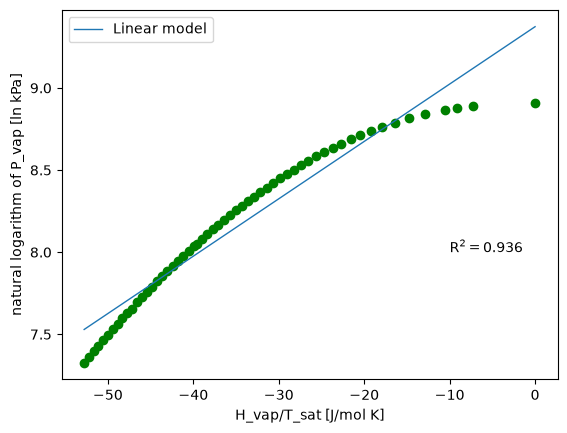

In [24]:
# Lets look at Hvaps with CO2

Hvaps = df["H_vap [J/g]"].to_numpy().reshape(-1,1)
# Change the unit of Hvaps to J/mol by multiplying wit molecular weight
mw_CO2 = 44.01 # g/mol
Hvaps = Hvaps * mw_CO2 # unit = J/mol

ln_P = np.log(Ps)
neg_Hvaps_T = -Hvaps/(Ts + 273.15)

lr_model_negH = LinearRegression().fit(neg_Hvaps_T, ln_P)

x_pred = np.linspace(min(neg_Hvaps_T), max(neg_Hvaps_T), 100)
y_pred = lr_model_negH.predict(x_pred)
R2 = lr_model_negH.score(neg_Hvaps_T, ln_P)

plt.figure
plt.plot(neg_Hvaps_T, ln_P, 'co', color = "green")
plt.plot(x_pred, y_pred, linewidth=1, label='Linear model')
plt.text(-10, 8, 'R$^2 = $' + str(np.round(R2, 3)))
plt.xlabel('H_vap/T_sat [J/mol K]')
plt.ylabel('natural logarithm of P_vap [ln kPa]')
plt.legend()
plt.show()


In [21]:
from sklearn.metrics import mean_squared_error

print("Coefficient: ", lr_model_negH.coef_)
print("Intercept: ", lr_model_negH.intercept_)

y_hat = lr_model_negH.predict(neg_Hvaps_T)   # 57 predictions, one per real point
print(y_hat.shape, ln_P.shape)              # both should be (57, 1)
rmse = np.sqrt(mean_squared_error(ln_P, y_hat))
print("RMSE: ", rmse)

Coefficient:  [[0.03493331]]
Intercept:  [9.37304829]
(57, 1) (57, 1)
RMSE:  0.11891139781458512
